# Supervised Learning and K Nearest Neighbors Exercises

## Introduction

We will be using customer churn data from the telecom industry for the first week's exercises. The data file is called
`Orange_Telecom_Churn_Data.csv`. We will load this data together, do some preprocessing, and use K-nearest neighbors to predict customer churn based on account characteristics.

In [46]:
from __future__ import print_function
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Question 1

* Begin by importing the data. Examine the columns and data.
* Notice that the data contains a state, area code, and phone number. Do you think these are good features to use when building a machine learning model? Why or why not?

We will not be using them, so they can be dropped from the data.

In [47]:
df = pd.read_csv("orange_telecom_churn_data.csv")
df.head(5)

,state,account_length,area_code,phone_number,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [48]:
df.shape

(5000, 21)

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   state                          5000 non-null   object 
 1   account_length                 5000 non-null   int64  
 2   area_code                      5000 non-null   int64  
 3   phone_number                   5000 non-null   object 
 4   intl_plan                      5000 non-null   object 
 5   voice_mail_plan                5000 non-null   object 
 6   number_vmail_messages          5000 non-null   int64  
 7   total_day_minutes              5000 non-null   float64
 8   total_day_calls                5000 non-null   int64  
 9   total_day_charge               5000 non-null   float64
 10  total_eve_minutes              5000 non-null   float64
 11  total_eve_calls                5000 non-null   int64  
 12  total_eve_charge               5000 non-null   f

In [50]:
df.iloc[[0]].T

,0
state,KS
account_length,128
area_code,415
phone_number,382-4657
intl_plan,no
voice_mail_plan,yes
number_vmail_messages,25
total_day_minutes,265.1
total_day_calls,110
total_day_charge,45.07


- The state, area code, and phone number will not be suitable columns for providing features for machine learning, since training models only require measurable numerical data. These specific columns are used more as identifiers or columns that uniquely identify each data point.

In [51]:
cols_to_drop = ['state', 'area_code', 'phone_number']
df.drop(cols_to_drop, axis=1, inplace=True)

In [52]:
df.columns

Index(['account_length', 'intl_plan', 'voice_mail_plan',
       'number_vmail_messages', 'total_day_minutes', 'total_day_calls',
       'total_day_charge', 'total_eve_minutes', 'total_eve_calls',
       'total_eve_charge', 'total_night_minutes', 'total_night_calls',
       'total_night_charge', 'total_intl_minutes', 'total_intl_calls',
       'total_intl_charge', 'number_customer_service_calls', 'churned'],
      dtype='object')

## Question 2

* Notice that some of the columns are categorical data and some are floats. These features will need to be numerically encoded using one of the methods from the lecture.
* Finally, remember from the lecture that K-nearest neighbors requires scaled data. Scale the data using one of the scaling methods discussed in the lecture.

In [53]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

In [54]:
df_encoded = df.copy()

# One-hot encoding; convert categorical to numerical
df_encoded = pd.get_dummies(df_encoded, columns=['intl_plan', 'voice_mail_plan'], drop_first=True)
df_encoded['churned'] = df_encoded['churned'].astype(int)


In [55]:
X = df_encoded.drop('churned', axis=1)
y = df_encoded['churned']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

X_scaled_df.head(5)

,account_length,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,intl_plan_yes,voice_mail_plan_yes
0,0.698941,1.273145,1.573802,0.502824,1.574074,-0.064032,-0.060077,-0.063849,0.876999,-0.446928,0.876286,-0.094809,-0.584236,-0.095509,-0.436676,-0.323240,1.667120
1,0.169849,1.346973,-0.346802,1.158422,-0.347082,-0.101621,0.141693,-0.101089,1.068992,0.154374,1.069818,1.245227,-0.584236,1.245982,-0.436676,-0.323240,1.667120
2,0.925695,-0.572549,1.171125,0.704546,1.171286,-1.571562,0.494791,-1.572084,-0.748012,0.204483,-0.746737,0.701969,0.229917,0.695971,-1.202236,-0.323240,-0.599837
3,-0.409634,-0.572549,2.210292,-1.463971,2.210457,-2.744745,-0.614946,-2.745155,-0.069110,-0.547145,-0.069377,-1.326194,1.044069,-1.329681,0.328885,3.093675,-0.599837
4,-0.636388,-0.572549,-0.252163,0.654116,-0.252115,-1.035419,1.100103,-1.034426,-0.267041,1.056327,-0.267307,-0.058592,-0.584236,-0.055264,1.094445,3.093675,-0.599837


## Question 3

* Separate the feature columns (everything except `churned`) from the label (`churned`). This will create two tables.
* Fit a K-nearest neighbors model with a value of `k=3` to this data and predict the outcome on the same data.

In [56]:
X = df_encoded.drop('churned', axis=1)
y = df_encoded['churned']

In [57]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X, y)

predictions = knn.predict(X)
accuracy = (knn.score(X, y)) * 100

print(f"Model Accuracy: {accuracy:.2f}%")

Model Accuracy: 91.64%


## Question 4

Ways to measure error haven't been discussed in class yet, but accuracy is an easy one to understand--it is simply the percent of labels that were correctly predicted (either true or false).

* Write a function to calculate accuracy using the actual and predicted labels.
* Using the function, calculate the accuracy of this K-nearest neighbors model on the data.

In [58]:
import numpy as np

def calculate_accuracy(y_actual, y_pred):
    actual = np.array(y_actual)
    pred = np.array(y_pred)
    return np.mean(actual == pred) * 100

accuracy_score = calculate_accuracy(y, predictions)
print(f"Model Accuracy: {accuracy_score:.2f}%")

Model Accuracy: 91.64%


In [59]:
def calculate_k_nearest_accuracy(actual_labels, predicted_labels):
    correct_predictions = (actual_labels == predicted_labels).sum()
    total_predictions = len(actual_labels)
    accuracy = (correct_predictions / total_predictions) * 100
    return accuracy

accuracy_score = calculate_k_nearest_accuracy(y, predictions)
print(f"Model Accuracy: {accuracy_score:.2f}%")

Model Accuracy: 91.64%


## Question 5

* Fit the K-nearest neighbors model again with `n_neighbors=3` but this time use distance for the weights. Calculate the accuracy using the function you created above.
* Fit another K-nearest neighbors model. This time use uniform weights but set the power parameter for the Minkowski distance metric to be 1 (`p=1`) i.e. Manhattan Distance.

When weighted distances are used for part 1 of this question, a value of 1.0 should be returned for the accuracy. Why do you think this is? *Hint:* we are predicting on the data and with KNN the model *is* the data. We will learn how to avoid this pitfall in the next lecture.

In [60]:
# KNN by distance
knn_distance_weights = KNeighborsClassifier(n_neighbors=3, weights='distance')
knn_distance_weights.fit(X_scaled, y)

predictions_distance = knn_distance_weights.predict(X_scaled)
accuracy_distance = calculate_k_nearest_accuracy(y, predictions_distance)
print(f"Distance KNN Model Accuracy: {accuracy_distance:.2f}%")

Distance KNN Model Accuracy: 100.00%


In [61]:
# KNN by Manhattan distance
knn_manhattan = KNeighborsClassifier(n_neighbors=3, weights='uniform', p=1)
knn_manhattan.fit(X_scaled, y)

predictions_manhattan = knn_manhattan.predict(X_scaled)
accuracy_manhattan = calculate_k_nearest_accuracy(y, predictions_manhattan)
print(f"Manhattan Distance KNN Model Accuracy: {accuracy_manhattan:.2f}%")

Manhattan Distance KNN Model Accuracy: 94.16%


## Question 6

* Fit a K-nearest neighbors model using values of `k` (`n_neighbors`) ranging from 1 to 20. Use uniform weights (the default). The coefficient for the Minkowski distance (`p`) can be set to either 1 or 2--just be consistent. Store the accuracy and the value of `k` used from each of these fits in a list or dictionary.
* Plot (or view the table of) the `accuracy` vs `k`. What do you notice happens when `k=1`? Why do you think this is? *Hint:* it's for the same reason discussed above.

In [62]:
accuracies = []
k_values = range(1, 21)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, weights='uniform', p=2)
    knn.fit(X_scaled, y)
    accuracy = knn.score(X_scaled, y)
    accuracies.append(accuracy)

k_accuracy_dict = dict(zip(k_values, accuracies))

results_df = pd.DataFrame({'k': k_values, 'accuracy': accuracies})
print("Accuracy for different k values:")
print(results_df.to_string(index=False))

Accuracy for different k values:
 k  accuracy
 1    1.0000
 2    0.9218
 3    0.9396
 4    0.9120
 5    0.9280
 6    0.9094
 7    0.9194
 8    0.9052
 9    0.9144
10    0.9024
11    0.9112
12    0.9002
13    0.9086
14    0.8984
15    0.9032
16    0.8944
17    0.8998
18    0.8934
19    0.8996
20    0.8928


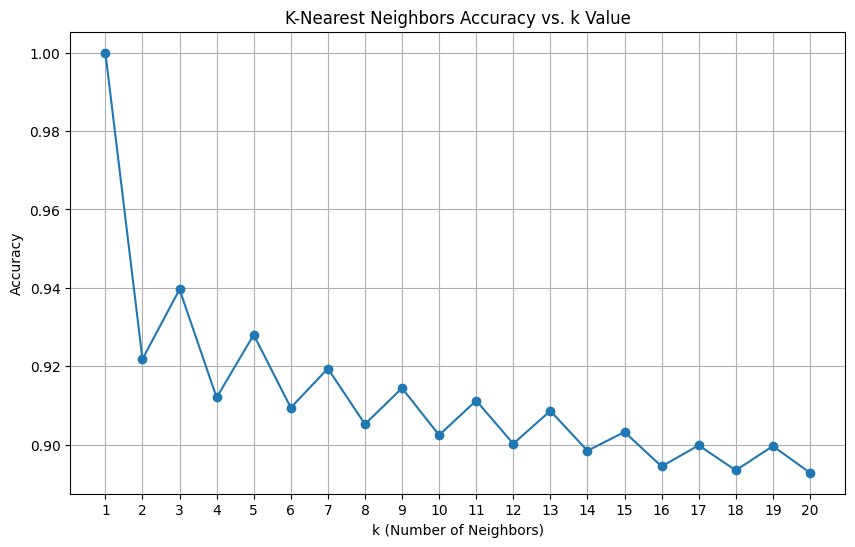

In [63]:
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o')
plt.title('K-Nearest Neighbors Accuracy vs. k Value')
plt.xlabel('k (Number of Neighbors)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid(True)
plt.show()

Observation: When k is equal to 1, the accuracy will be 1.0 since the closest neighbor recognized by the model is the data point itself. Therefore, the model will always correctly classify every training instance, leading to 100% accuracy.

## Supplementary
1. Include Classification Report and Confusion Matrix
2. Evaluate performance of using GridSearch vs Random Search in terms of Accuracy for Training and Testing.

In [64]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np

In [65]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

In [66]:
# Grid
param_grid = {
    'n_neighbors': np.arange(1, 21),
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}
knn = KNeighborsClassifier()

GridSearch

In [67]:
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'n_neighbors': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20]),
                         'p': [1, 2], 'weights': ['uniform', 'distance']},
             scoring='accuracy')

In [68]:
best_knn_grid = grid_search.best_estimator_
y_train_pred_grid = best_knn_grid.predict(X_train)
y_test_pred_grid = best_knn_grid.predict(X_test)

In [69]:
print("\nGridSearch - Training Performance:")
print(f"Accuracy: {accuracy_score(y_train, y_train_pred_grid):.4f}")
print("Classification Report:\n", classification_report(y_train, y_train_pred_grid))
print("Confusion Matrix:\n", confusion_matrix(y_train, y_train_pred_grid))

print("\nGridSearch - Testing Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_test_pred_grid):.4f}")
print("Classification Report:\n", classification_report(y_test, y_test_pred_grid))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred_grid))


GridSearch - Training Performance:
Accuracy: 1.0000
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      3000
           1       1.00      1.00      1.00       500

    accuracy                           1.00      3500
   macro avg       1.00      1.00      1.00      3500
weighted avg       1.00      1.00      1.00      3500

Confusion Matrix:
 [[3000    0]
 [   0  500]]

GridSearch - Testing Performance:
Accuracy: 0.9080
Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.98      0.95      1293
           1       0.79      0.45      0.57       207

    accuracy                           0.91      1500
   macro avg       0.86      0.72      0.76      1500
weighted avg       0.90      0.91      0.90      1500

Confusion Matrix:
 [[1269   24]
 [ 114   93]]


RandomizedSearch

In [70]:
random_search = RandomizedSearchCV(knn, param_grid, n_iter=20, cv=5, scoring='accuracy', random_state=42, n_jobs=-1)
random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5, estimator=KNeighborsClassifier(), n_iter=20, n_jobs=-1,
                   param_distributions={'n_neighbors': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20]),
                                        'p': [1, 2],
                                        'weights': ['uniform', 'distance']},
                   random_state=42, scoring='accuracy')

In [ ]:
# Evaluate RandomizedSearchCV's best estimator
best_knn_random = random_search.best_estimator_

y_train_pred_random = best_knn_random.predict(X_train)
y_test_pred_random = best_knn_random.predict(X_test)

In [72]:
print("\nRandomSearch - Training Performance:")
print(f"Accuracy: {accuracy_score(y_train, y_train_pred_random):.4f}")
print("Classification Report:\n", classification_report(y_train, y_train_pred_random))
print("Confusion Matrix:\n", confusion_matrix(y_train, y_train_pred_random))

print("\nRandomSearch - Testing Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_test_pred_random):.4f}")
print("Classification Report:\n", classification_report(y_test, y_test_pred_random))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred_random))


RandomSearch - Training Performance:
Accuracy: 1.0000
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      3000
           1       1.00      1.00      1.00       500

    accuracy                           1.00      3500
   macro avg       1.00      1.00      1.00      3500
weighted avg       1.00      1.00      1.00      3500

Confusion Matrix:
 [[3000    0]
 [   0  500]]

RandomSearch - Testing Performance:
Accuracy: 0.9000
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.99      0.94      1293
           1       0.82      0.35      0.49       207

    accuracy                           0.90      1500
   macro avg       0.86      0.67      0.72      1500
weighted avg       0.89      0.90      0.88      1500

Confusion Matrix:
 [[1277   16]
 [ 134   73]]


In [73]:
print("\n--- Comparison ---")
print(f"GridSearch Test Accuracy: {accuracy_score(y_test, y_test_pred_grid):.4f}")
print(f"RandomSearch Test Accuracy: {accuracy_score(y_test, y_test_pred_random):.4f}")


--- Comparison ---
GridSearch Test Accuracy: 0.9080
RandomSearch Test Accuracy: 0.9000
